# ENG2040 assignment 1 - marketplace orders to a model-ready dataset

one notebook, one section per step. `uv run python run.py` checks the supplied files, rebuilds `data/marketplace.sqlite`, runs the engine comparison (`bench.py`) and this notebook, then hashes every output.

each step writes to `data/<step>/` plus a `resources.json`: runtime, peak memory of this kernel during the step (sampled every 10 ms), and file sizes. the small pieces every step uses (db connection, `track`, `rate` with wilson intervals, plot style) live in `helpers.py`.

In [1]:
import json, resource, sys, time
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from helpers import ROOT, DATA, DB, SPIKE, WEEKS, RED, GREY, q, read, mb, size, days, track, wilson, rate, add_lead, save

## step 1 - loading

in: `data/marketplace.sqlite` (built from `raw.sql` by the supplied `setup_db.py`)

out, in `data/01_load/`: `orders.parquet` (one row per order), `items.parquet` (one row per item, with product + seller attributes), `checks.csv`, `key_links.csv`, `bench.csv` (from `bench.py`)

### tables and keys

| table | rows | key | one row is |
|---|---|---|---|
| orders | 20,000 | order_id | an order |
| customers | 20,000 | customer_id | the customer record of one order. `customer_unique_id` is the person across orders |
| order_items | 22,662 | order_id + order_item_id | one item bought. 2 of the same product = 2 rows |
| order_payments | 20,875 | order_id + payment_sequential | one payment, in centavos |
| order_reviews | 19,966 | review_id + order_id | one review |
| products / sellers | 11,334 / 2,071 | product_id / seller_id | catalogue rows, linked from items |
| category_translation | 73 | category name | portuguese -> english |

orders is the grain. items, payments and reviews are one-to-many, so they are rolled up to one row per order before joining. joining them raw multiplies rows (3 items x 2 payments = 6 rows) and double counts totals. the db is loaded with foreign keys off, so nothing guarantees the keys match. checked first:

In [2]:
counts = pd.Series({t: q(f"select count(*) n from {t}").n[0] for t in q("select name from sqlite_master where type='table'").name})
L = {
    "orders without a customer row": "orders o left join customers c using (customer_id) where c.customer_id is null",
    "customers without an order": "customers c left join orders o using (customer_id) where o.order_id is null",
    "items without an order": "order_items i left join orders o using (order_id) where o.order_id is null",
    "payments without an order": "order_payments p left join orders o using (order_id) where o.order_id is null",
    "reviews without an order": "order_reviews r left join orders o using (order_id) where o.order_id is null",
    "items without a product row": "order_items i left join products p using (product_id) where p.product_id is null",
    "items without a seller row": "order_items i left join sellers s using (seller_id) where s.seller_id is null",
    "orders with no items": "orders o where order_id not in (select order_id from order_items)",
    "orders with no reviews": "orders o where order_id not in (select order_id from order_reviews)",
    "orders with 2+ reviews": "(select order_id from order_reviews group by 1 having count(*) > 1)",
    "customer_id on 2+ orders": "(select customer_id from orders group by 1 having count(*) > 1)",
    "duplicate orders (same customer, time, status)": "(select 1 from orders group by customer_id, order_purchase_timestamp, order_status having count(*) > 1)",
    "repeated item rows (same order, product, seller, price)": "(select 1 from order_items group by order_id, product_id, seller_id, price, freight_value having count(*) > 1)",
}
links = pd.Series({k: q(f"select count(*) n from {v}").n[0] for k, v in L.items()})
print(counts.to_dict())
links

{'category_translation': 73, 'customers': 20000, 'order_items': 22662, 'order_payments': 20875, 'order_reviews': 19966, 'orders': 20000, 'products': 11334, 'sellers': 2071}


orders without a customer row                              769
customers without an order                                 769
items without an order                                       0
payments without an order                                    0
reviews without an order                                     0
items without a product row                                910
items without a seller row                                 893
orders with no items                                       142
orders with no reviews                                     147
orders with 2+ reviews                                     111
customer_id on 2+ orders                                     0
duplicate orders (same customer, time, status)               0
repeated item rows (same order, product, seller, price)    998
dtype: int64

- every item, payment and review points at a real order, so nothing is lost when they roll up
- the other way has gaps: orders with no customer row, no items, items whose product or seller row is missing. so every join is a left join from the order (or item) side. a missing customer gives nulls, the order stays. dropping is a cleaning decision, not a loading one
- no duplicate orders and no customer record shared by two orders
- repeated item rows are how quantity is stored (2 of the same product = 2 rows with their own `order_item_id`), not duplicates

the sql (`sql/orders.sql`) aggregates items, payments and reviews per order inside sqlite and left joins them onto orders. sums skip nulls, so null counts sit next to each sum. `payment_value` stays in integer centavos so totals are exact. the plan shows each group by walks the index on `order_id` in order, so no sort of the whole table (the `count(distinct ...)` per order still needs a small temporary b-tree), and each aggregate is joined back by an index lookup:

In [3]:
SQL = (ROOT / "sql" / "orders.sql").read_text()
print(q("explain query plan " + SQL).detail.str.cat(sep="\n"))

MATERIALIZE it
SCAN order_items USING INDEX sqlite_autoindex_order_items_1
USE TEMP B-TREE FOR count(DISTINCT)
USE TEMP B-TREE FOR count(DISTINCT)
MATERIALIZE pay
SCAN order_payments USING INDEX sqlite_autoindex_order_payments_1
MATERIALIZE rev
SCAN order_reviews USING COVERING INDEX order_reviews_order_id
SCAN o
SEARCH c USING INDEX sqlite_autoindex_customers_1 (customer_id=?) LEFT-JOIN
SEARCH it USING AUTOMATIC COVERING INDEX (order_id=?) LEFT-JOIN
SEARCH pay USING AUTOMATIC COVERING INDEX (order_id=?) LEFT-JOIN
SEARCH rev USING AUTOMATIC COVERING INDEX (order_id=?) LEFT-JOIN


In [4]:
OUT, done = track("01_load")
orders = q(SQL)
items = q((ROOT / "sql" / "items.sql").read_text())
for df, cols in [(orders, ["has_customer"]), (items, ["has_product", "has_seller"])]:
    df[cols] = df[cols].astype("bool[pyarrow]")

# every count and total in the db must survive into the output
db = q("""select (select count(*) from orders), (select count(distinct order_id) from orders), (select count(*) from order_items),
  (select sum(price) from order_items), (select sum(freight_value) from order_items), (select count(*) from order_payments),
  (select sum(payment_value) from order_payments), (select count(*) from order_reviews)""").iloc[0].tolist()
out = [len(orders), orders.order_id.nunique(), orders.n_items.sum(), orders.price_sum.sum(), orders.freight_sum.sum(),
       orders.n_payments.sum(), orders.payment_sum_centavos.sum(), orders.n_reviews.sum()]
checks = pd.DataFrame({"db": db + [db[2], db[3]], "output": out + [len(items), items.price.sum()]},
                      index=["orders", "unique order_id", "items", "price BRL", "freight BRL", "payments", "payment centavos", "reviews",
                             "items.parquet rows", "items.parquet price BRL"])
checks["ok"] = np.isclose(checks.db.astype(float), checks.output.astype(float), rtol=1e-9)
assert checks.ok.all()

orders.to_parquet(OUT / "orders.parquet", index=False)
items.to_parquet(OUT / "items.parquet", index=False)
assert pd.read_parquet(OUT / "orders.parquet", dtype_backend="pyarrow").equals(orders)  # parquet keeps types and values
checks.to_csv(OUT / "checks.csv")
links.rename("n").to_csv(OUT / "key_links.csv")
print(done(in_memory_MB={"orders": size(orders), "items": size(items)}))
checks

{'step': '01_load', 'seconds': 0.22, 'rss_start_MB': 164.72, 'rss_peak_MB': 235.52, 'rss_peak_above_start_MB': 70.8, 'in_memory_MB': {'orders': np.float64(7.02), 'items': np.float64(5.87)}, 'saved_MB': {'bench.csv': 0.0, 'bench_raw.csv': 0.01, 'checks.csv': 0.0, 'engine_comparison.png': 0.03, 'items.parquet': 1.86, 'key_links.csv': 0.0, 'orders.parquet': 3.29}}


,db,output,ok
orders,2.000000e+04,2.000000e+04,True
unique order_id,2.000000e+04,2.000000e+04,True
items,2.266200e+04,2.266200e+04,True
price BRL,5.444621e+07,5.444621e+07,True
freight BRL,1.051506e+07,1.051506e+07,True
payments,2.087500e+04,2.087500e+04,True
payment centavos,2.805245e+08,2.805245e+08,True
reviews,1.996600e+04,1.996600e+04,True
items.parquet rows,2.266200e+04,2.266200e+04,True
items.parquet price BRL,5.444621e+07,5.444621e+07,True


### why this way: engine, memory, runtime, storage

the same one-row-per-order table built 7 ways, at 1x, 3x and 10x the data (the extract copied with new ids, same schema and indexes). each run is its own fresh process, 3 repeats, median. a baseline run that only imports pandas and connects is subtracted, so the numbers are what the work itself costs. code in `bench.py`.

- **pandas**: read every table whole, group by and merge in pandas
- **sqlite sql (adbc)**: `sql/orders.sql` runs inside sqlite, only the 20,000 result rows reach python
- **sqlite sql (sqlite3 driver)**: the same, through python's built-in driver
- **duckdb**: a columnar engine that can read the sqlite file directly, or parquet copies of the tables. also on one thread, and writing its result to a file instead of into python

estimate written before running. first version (sqlite3 driver): pandas should need ~2x the memory of sql at 10x. duckdb (added later): fastest, memory close to sqlite sql since it also only returns the aggregate.

                                          MB_above_baseline                 seconds            
scale                                                    1       3       10      1     3     10
approach                                                                                       
duckdb sql on parquet                                 97.60  184.50  469.94    0.03  0.07  0.12
duckdb sql on parquet, 1 thread                       57.20  106.69  313.66    0.03  0.07  0.22
duckdb sql on parquet, streamed to a file             99.68  188.81  481.79    0.04  0.09  0.15
duckdb sql on sqlite                                 101.09  187.20  457.16    0.04  0.10  0.25
pandas (adbc reads whole tables)                      51.82  130.48  405.24    0.08  0.25  0.68
sqlite sql (adbc)                                     24.51   50.59  120.08    0.10  0.43  1.86
sqlite sql (python sqlite3 driver)                    53.85  141.64  420.72    0.24  0.93  3.97


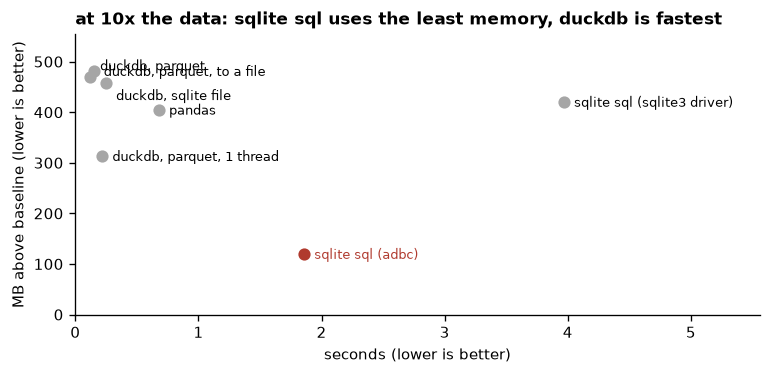

In [5]:
bench = pd.read_csv(OUT / "bench.csv")
b10 = bench[bench.scale == 10].set_index("approach")
print(bench.pivot_table(index="approach", columns="scale", values=["MB_above_baseline", "seconds"]).round(2).to_string())

short = {"sqlite sql (adbc)": "sqlite sql (adbc)", "pandas (adbc reads whole tables)": "pandas", "duckdb sql on parquet": "duckdb, parquet",
         "duckdb sql on sqlite": "duckdb, sqlite file", "duckdb sql on parquet, 1 thread": "duckdb, parquet, 1 thread",
         "sqlite sql (python sqlite3 driver)": "sqlite sql (sqlite3 driver)", "duckdb sql on parquet, streamed to a file": "duckdb, parquet, to a file"}
nudge = {"duckdb sql on parquet": (6, 4), "duckdb sql on sqlite": (6, -10)}
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for name, r in b10.iterrows():
    pick = name == "sqlite sql (adbc)"
    ax.scatter(r.seconds, r.MB_above_baseline, color=RED if pick else GREY, s=40, zorder=3)
    ax.annotate(short[name], (r.seconds, r.MB_above_baseline), xytext=nudge.get(name, (6, -3)), textcoords="offset points", color=RED if pick else "black", fontsize=8)
ax.set(xlabel="seconds (lower is better)", ylabel="MB above baseline (lower is better)", xlim=(0, b10.seconds.max() * 1.4), ylim=(0, b10.MB_above_baseline.max() * 1.15))
ax.set_title("at 10x the data: sqlite sql uses the least memory, duckdb is fastest")
save(fig, OUT / "engine_comparison.png")

the first estimate was wrong. it was made with python's built-in `sqlite3` driver, and with it sql and pandas need the same memory (about 420 vs 405 MB at 10x). that driver makes a python object per value: the 20,000 result rows take about 20 MB as python objects against 7 MB as a dataframe. adbc hands the result over as arrow columns instead, and then sql needs under a third of pandas' memory (120 vs 405 MB at 10x). the gap grows with size since pandas holds every raw row.

duckdb was a surprise the other way. at 10x it is 6-16x faster than pandas and sqlite sql, but holds 310-480 MB, close to pandas, even on one thread. its hash tables for the group bys and joins cost more than the result. writing the result straight to a parquet file instead of into python doesnt help either (480 MB). capping its memory (`memory_limit`) made the query fail, so that one is not in the table.

so nothing wins on both. sqlite sql through adbc is the pick: memory decides whether a step fits on a machine at all, and 2 seconds at 10x doesnt matter for a batch step. if runtime mattered more, duckdb would be the pick.

storage of the orders table:

In [6]:
tmp = OUT / "_tmp.csv"
orders.to_csv(tmp, index=False)
print({"csv MB": mb(tmp.stat().st_size), "parquet MB": mb((OUT / "orders.parquet").stat().st_size), "sqlite db MB": mb(DB.stat().st_size)})
tmp.unlink()

{'csv MB': 5.25, 'parquet MB': 3.29, 'sqlite db MB': 24.36}


parquet is smaller and keeps the types (timestamps, booleans, nulls) that csv would turn into text.

## step 2 - cleaning

in: `data/01_load/*.parquet`, payments and category translation from the db

out, in `data/02_clean/`: `orders_clean.parquet` (all 20,000 orders, label or `unlabelled_reason`), `items_clean.parquet`, `changes.parquet` (every changed value: key, column, rule, old, new), `cleaning_summary.csv`, `record_accounting.csv`, `fix_evidence.csv`, `profile.csv`, `payment_reconciliation.csv`

rule for every problem, strongest first:
1. **fix** only when an independent record shows the true value
2. **set missing** when the value is wrong but nothing shows the true one
3. **flag** when the field feeds neither labels nor features

no order is deleted.

In [7]:
OUT, done = track("02_clean")
o, it = read("01_load/orders", dtype_backend="pyarrow"), read("01_load/items", dtype_backend="pyarrow")
pay, tr = q("select * from order_payments"), q("select * from category_translation")
it["item_key"] = it.order_id + "/" + it.order_item_id.astype("string[pyarrow]")
log = []

def change(table, df, key, col, mask, new, rule):
    # set new values where mask is true, log every old -> new
    m = mask.fillna(False).astype(bool)
    if not m.any():
        return
    new = new if isinstance(new, pd.Series) else pd.Series(new, index=df.index, dtype=df[col].dtype)
    log.append(pd.DataFrame({"table": table, "key": df.loc[m, key].astype(str), "column": col, "rule": rule,
                             "old": df.loc[m, col].astype(str), "new": new[m].astype(str)}))
    df.loc[m, col] = new[m]

TS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
UF = set("AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO".split())
SIZE = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
PLACEHOLDER = ["product_photos_qty", "product_name_lenght", "product_description_lenght"]
parse = lambda s: pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")
d = {c: parse(o[c]) for c in TS}
st = o.order_status.str.strip().str.lower()
profile = pd.Series({
    "status with spaces or capitals": (o.order_status != st).sum(),
    "status not_reported": (st == "not_reported").sum(),
    "impossible date 2018-02-30": o[TS].eq("2018-02-30 10:00:00").any(axis=1).sum(),
    "delivered before approval": (d["order_delivered_customer_date"] < d["order_approved_at"]).sum(),
    "  exactly 7 days before": ((d["order_approved_at"] - d["order_delivered_customer_date"]) == pd.Timedelta(days=7)).sum(),
    "carrier pickup before approval": (d["order_delivered_carrier_date"] < d["order_approved_at"]).sum(),
    "cancelled but has a delivery date": ((st == "canceled") & d["order_delivered_customer_date"].notna()).sum(),
    "customer state not brazilian (ZZ, blank)": (~o.customer_state.str.strip().str.upper().isin(UF) & o.customer_state.notna()).sum(),
    "item price < 0 / > 5000": f"{(it.price < 0).sum()} / {(it.price > 5000).sum()}",
    "item freight < 0 / > 500": f"{(it.freight_value < 0).sum()} / {(it.freight_value > 500).sum()}",
    "item price / freight missing": f"{it.price.isna().sum()} / {it.freight_value.isna().sum()}",
    "category unmapped_category": (it.product_category_name == "unmapped_category").sum(),
    "size or weight <= 0": (it[SIZE] <= 0).any(axis=1).sum(),
    "size > 200 cm or weight > 100 kg": ((it[SIZE[1:]] > 200).any(axis=1) | (it.product_weight_g > 100000)).sum(),
    "photos / name / description = -1": (it[PLACEHOLDER] == -1).any(axis=1).sum(),
    "payment < 0 / missing / unclassified": f"{(pay.payment_value < 0).sum()} / {pay.payment_value.isna().sum()} / {(pay.payment_type == 'unclassified_payment').sum()}",
    "payment installments -1 / 0": f"{(pay.payment_installments == -1).sum()} / {(pay.payment_installments == 0).sum()}",
}).astype(str)
profile

status with spaces or capitals                          783
status not_reported                                     804
impossible date 2018-02-30                              797
delivered before approval                               812
  exactly 7 days before                                 803
carrier pickup before approval                          270
cancelled but has a delivery date                       733
customer state not brazilian (ZZ, blank)                838
item price < 0 / > 5000                           408 / 417
item freight < 0 / > 500                          458 / 473
item price / freight missing                      439 / 427
category unmapped_category                              674
size or weight <= 0                                     632
size > 200 cm or weight > 100 kg                        783
photos / name / description = -1                        690
payment < 0 / missing / unclassified        975 / 945 / 913
payment installments -1 / 0             

### prices: which fix does the evidence support

payments are an independent record of what the customer paid. for orders with exactly one kind of price problem: after a fix, does price + freight equal the payment to the centavo? on clean orders this holds for about 90% (the rest is mostly the 7.23 gap, see below), so a correct fix should land near 90%.

the thresholds sit in gaps: normal prices top out at 4,690 and the big ones start at 6,499. freight 314 vs 1,000.

In [8]:
oi = o.set_index("order_id")
paid = oi.payment_sum_centavos / 100
complete = oi.eval("n_price_null == 0 and n_freight_null == 0 and n_payment_null == 0 and n_items > 0")
kind = pd.DataFrame({"order_id": it.order_id, "price < 0": it.price < 0, "price > 5000": it.price > 5000,
                     "freight < 0": it.freight_value < 0, "freight > 500": it.freight_value > 500}).fillna(False).groupby("order_id").any()
match = lambda p, f, ids: round(float(((paid[ids] - (p + f).groupby(it.order_id).sum()[ids]).abs() <= 0.01).mean()), 3)
big = lambda x, cap, k: x.where(~(x > cap).fillna(False), x / k)
p, f = it.price, it.freight_value
fixes = {"none": (p, f), "abs": (p.abs(), f.abs()), "/100": (big(p, 5000, 100), big(f, 500, 100)), "/1000": (big(p, 5000, 1000), big(f, 500, 1000))}
clean_ids = kind.index[~kind.any(axis=1)].intersection(complete.index[complete])
evidence = pd.DataFrame({k: {"orders": len(ids := kind.index[kind[k] & (kind.sum(axis=1) == 1)].intersection(complete.index[complete])),
                             **{fx: match(*v, ids) for fx, v in fixes.items()}} for k in kind}).T
evidence.loc["clean orders (reference)"] = [len(clean_ids), match(p, f, clean_ids), np.nan, np.nan, np.nan]

# second witness: the same product sold in other orders at a normal price
ok = (p > 0) & (p <= 5000)
usual = p[ok].groupby(it.product_id[ok]).median()
for name, bad, fixed in [("price < 0", p < 0, p.abs()), ("price > 5000", p > 5000, p / 1000)]:
    u = it.product_id[bad.fillna(False)].map(usual)
    print(f"{name}: product sold elsewhere for {u.notna().sum()} items, fixed price = its usual price for {(fixed[u.index].round(2) == u.round(2)).sum()}")
evidence

price < 0: product sold elsewhere for 255 items, fixed price = its usual price for 163
price > 5000: product sold elsewhere for 277 items, fixed price = its usual price for 178


,orders,none,abs,/100,/1000
price < 0,366.0,0.000,0.872,0.0,0.000
price > 5000,384.0,0.003,0.003,0.0,0.935
freight < 0,413.0,0.000,0.903,0.0,0.000
freight > 500,441.0,0.000,0.000,0.0,0.884
clean orders (reference),16499.0,0.900,NaN,NaN,NaN


abs for negatives, /1000 for the big values. /100 matches nothing, so the obvious guess (centavos typed as reais) is wrong. the match rates for abs and /1000 sit at the clean-order level, and the same products sold elsewhere agree.

### product sizes and weights

the same 1000x pattern is in the catalogue. lengths top out at 105-118 cm and the big ones start at 2,000 cm, all multiples of 1000. weights run to 30 kg, then three values (40.4, 50, 100 kg), and above 100 kg every value is a multiple of 1000. there is no payment for a product, so the witness is freight. a real 400 kg parcel would cost a lot to ship.

In [9]:
w, fr = it.product_weight_g, it.freight_value.where((it.freight_value >= 0) & (it.freight_value <= 500))
lo, hi = (w[w > 100000] / 1000).quantile([0.25, 0.75])
pd.Series({"items listed over 100 kg": fr[w > 100000].median(), f"items of {lo:.0f}-{hi:.0f} g": fr[w.between(lo, hi)].median(),
           "items of 20-30 kg": fr[w.between(20000, 30000)].median()}, name="median freight BRL")

items listed over 100 kg    15.245
items of 400-1383 g         16.110
items of 20-30 kg           74.560
Name: median freight BRL, dtype: float64

the 'over 100 kg' items ship like 0.4-1.4 kg items, nothing like real 20-30 kg ones. so the raw values are wrong. but freight only says roughly how heavy, it cant confirm the exact value the way payments confirmed prices. so these go to missing, not /1000. those three could be real and stay. `-1` is the only negative value photo count and name/description length ever take, a placeholder for unknown.

### apply the rules

In [10]:
change("orders", o, "order_id", "order_status", o.order_status != st, st, "status: strip + lowercase")
for c in TS:
    change("orders", o, "order_id", c, o[c].notna() & parse(o[c]).isna(), None, "impossible calendar date -> missing")
    o[c] = parse(o[c])
for df, table, key, col in [(o, "orders", "order_id", "customer_state"), (it, "items", "item_key", "seller_state")]:
    s = df[col].str.strip().str.upper()
    change(table, df, key, col, df[col] != s, s, "state: strip + uppercase")
    change(table, df, key, col, ~df[col].isin(UF) & df[col].notna(), None, "not a brazilian state (ZZ, blank) -> missing")
for c, cap in [("price", 5000), ("freight_value", 500)]:
    change("items", it, "item_key", c, it[c] < 0, it[c].abs(), "negative -> abs (checked against payments)")
    change("items", it, "item_key", c, it[c] > cap, it[c] / 1000, "1000x -> /1000 (checked against payments)")
cat = it.product_category_name.str.strip().str.lower()
change("items", it, "item_key", "product_category_name", it.product_category_name != cat, cat, "category: strip + lowercase")
change("items", it, "item_key", "product_category_name", it.product_category_name == "unmapped_category", None, "placeholder category -> missing")
for c, cap in zip(SIZE, [100000, 200, 200, 200]):
    change("items", it, "item_key", c, it[c] <= 0, None, "size or weight <= 0 -> missing")
    change("items", it, "item_key", c, it[c] > cap, None, "1000x size or weight (freight says impossible) -> missing")
for c in PLACEHOLDER:
    change("items", it, "item_key", c, it[c] == -1, None, "-1 placeholder -> missing")

# a zip prefix sits in one state. a missing state comes back from the zip if that zip is seen elsewhere with exactly one state
zs = pd.concat([o[["customer_zip_code_prefix", "customer_state"]].set_axis(["zip", "state"], axis=1),
                it[["seller_zip_code_prefix", "seller_state"]].set_axis(["zip", "state"], axis=1)]).dropna()
n = zs.groupby("zip").state.nunique()
zmap = zs[zs.zip.isin(n.index[n == 1])].drop_duplicates("zip").set_index("zip").state
print("zip prefixes:", len(n), "| with 2+ states (not used):", int((n > 1).sum()))
o["customer_state_recovered"] = (o.customer_state.isna() & o.customer_zip_code_prefix.isin(zmap.index)).fillna(False).astype("bool[pyarrow]")
change("orders", o, "order_id", "customer_state", o.customer_state_recovered, o.customer_zip_code_prefix.map(zmap), "missing state -> from zip prefix")
change("items", it, "item_key", "seller_state", it.seller_state.isna() & it.seller_zip_code_prefix.isin(zmap.index), it.seller_zip_code_prefix.map(zmap), "missing state -> from zip prefix")

tr["product_category_name"] = tr.product_category_name.str.strip().str.lower()
it = it.merge(tr, on="product_category_name", how="left")
print("categories without an english name:", it.product_category_name[it.product_category_name_english.isna()].dropna().unique())
changes = pd.concat(log, ignore_index=True)
summary = changes.groupby(["table", "column", "rule"], sort=False).size().rename("values").reset_index()
summary

zip prefixes: 8486 | with 2+ states (not used): 14
categories without an english name: <ArrowExtensionArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: string[pyarrow]


,table,column,rule,values
0,orders,order_status,status: strip + lowercase,783
1,orders,order_purchase_timestamp,impossible calendar date -> missing,165
2,orders,order_approved_at,impossible calendar date -> missing,152
3,orders,order_delivered_carrier_date,impossible calendar date -> missing,149
4,orders,order_delivered_customer_date,impossible calendar date -> missing,161
5,orders,order_estimated_delivery_date,impossible calendar date -> missing,170
6,orders,customer_state,state: strip + uppercase,877
7,orders,customer_state,"not a brazilian state (ZZ, blank) -> missing",838
8,items,seller_state,state: strip + uppercase,21507
9,items,seller_state,"not a brazilian state (ZZ, blank) -> missing",1031


### labels

`delivered_after_estimate` = 1 if the delivery calendar date is after the estimated calendar date, 0 if on or before it (brief: on the date is on time). local clock as recorded. an order only gets a label if its outcome is a usable completed delivery. the first rule that applies is the reason it stays unlabelled:

days late, labelled orders: min -77.0 max 188.0 | over 60 days late: 14


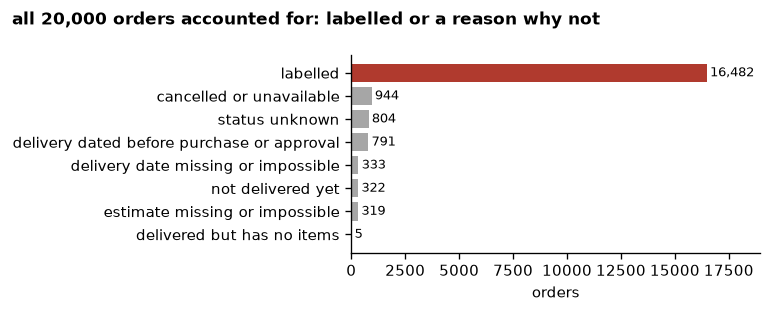

In [11]:
dl, ap, pu, es, s = o.order_delivered_customer_date, o.order_approved_at, o.order_purchase_timestamp, o.order_estimated_delivery_date, o.order_status
rules = {
    "cancelled or unavailable": s.isin(["canceled", "unavailable"]),
    "not delivered yet": s.isin(["shipped", "invoiced", "processing", "created", "approved"]),
    "status unknown": s == "not_reported",
    "delivered but has no items": o.n_items == 0,
    "delivery date missing or impossible": dl.isna(),
    "delivery dated before purchase or approval": (dl < ap) | (dl < pu),
    "estimate missing or impossible": es.isna(),
    "estimate dated before approval": es < ap,
}
reason = pd.Series(pd.NA, index=o.index, dtype="string[pyarrow]")
for r, m in rules.items():
    reason = reason.mask(reason.isna() & m.fillna(False).astype(bool), r)
o["unlabelled_reason"] = reason
o["days_late"] = (dl.dt.normalize() - es.dt.normalize()).dt.days.where(reason.isna())
o["delivered_after_estimate"] = (o.days_late > 0).astype("Int8").where(reason.isna())
accounting = o.unlabelled_reason.fillna("labelled").value_counts().rename("orders")
assert accounting.sum() == len(o) == 20000
print("days late, labelled orders: min", o.days_late.min(), "max", o.days_late.max(), "| over 60 days late:", (o.days_late > 60).sum())

fig, ax = plt.subplots(figsize=(6.5, 2.6))
a = accounting.sort_values()
ax.barh(a.index, a.values, color=[RED if i == "labelled" else GREY for i in a.index])
for i, v in enumerate(a.values):
    ax.text(v + 150, i, f"{v:,}", va="center", fontsize=8)
ax.set_xlim(0, a.max() * 1.15); ax.set_xlabel("orders")
fig.suptitle("all 20,000 orders accounted for: labelled or a reason why not", x=0.02, ha="left", fontsize=10, fontweight="bold")
save(fig, OUT / "record_accounting.png")

the extreme delays (up to 188 days late) are kept. status, delivery and estimate dates are all consistent for them and nothing says they are wrong. they are 14 orders, so the median delay doesnt move.

### totals from the cleaned items, checked against payments again

In [12]:
o = o.drop(columns=["price_sum", "freight_sum"]).join(it.groupby("order_id")[["price", "freight_value"]].sum().set_axis(["price_sum", "freight_sum"], axis=1), on="order_id")
gap = paid - o.set_index("order_id").eval("price_sum + freight_sum")
after = gap.abs() <= 0.01
before = (paid - oi.eval("price_sum + freight_sum")).abs() <= 0.01
neg_pay = pay.groupby("order_id").payment_value.min().lt(0)
g723 = (gap - 7.23).abs() <= 0.011
recon = pd.Series({"complete orders": complete.sum(), "match before cleaning": before[complete].sum(), "match after cleaning": after[complete].sum(),
                   "still not matching": (~after[complete]).sum(), "  with a negative payment": neg_pay.reindex(gap.index[complete & ~after], fill_value=False).sum(),
                   "  paid exactly 7.23 more": g723[complete].sum()})

# is the 7.23 tied to anything? compare its orders with all orders
pt = pay.assign(t=pay.payment_type.str.strip().str.lower()).groupby("order_id").t.agg(lambda x: "+".join(sorted(set(x))))
look = pd.DataFrame({"7.23": g723, "type": pt, "state": o.set_index("order_id").customer_state, "month": o.set_index("order_id").order_purchase_timestamp.dt.strftime("%Y-%m")})
share = lambda col, v: f"{(look[col] == v)[look['7.23']].mean():.0%} vs {(look[col] == v).mean():.0%}"
print("share of 7.23 orders vs all orders | credit card:", share("type", "credit_card"), "| boleto:", share("type", "boleto"),
      "| SP:", share("state", "SP"), "| RJ:", share("state", "RJ"), "| 2018-03:", share("month", "2018-03"))
recon

share of 7.23 orders vs all orders | credit card: 76% vs 72% | boleto: 15% vs 19% | SP: 40% vs 42% | RJ: 14% vs 13% | 2018-03: 6% vs 7%


complete orders              18122
match before cleaning        14845
match after cleaning         16302
still not matching            1820
  with a negative payment      919
  paid exactly 7.23 more       832
dtype: int64

the 7.23 gap sits on orders that look like every other order: same payment types, states and months, in about the same shares. it is never a payment row of its own. so it isnt clear which side is wrong, nothing is changed, and since it is spread evenly it cant bias a comparison between states, months or lead times.

### unresolved, and what it affects

- payments (negative values, `unclassified_payment`, -1 installments) are left alone. 0 installments is valid (brief). they cant be predictors and arent in the label, they only serve as a witness
- 7.23 extra on ~830 orders: left, spread evenly (above)
- carrier pickup before approval (270): flagged only, the carrier date is in neither label nor features
- `not_reported` (804) and the deliveries dated exactly 7 days before approval (782 of the 791 dated too early) stay unlabelled. a fix would be a guess. step 3 tests what happens if they are put back
- states not recoverable from the zip stay missing, mostly orders with no customer row. recovered ones are flagged
- `pc_gamer` and `portateis_cozinha_e_preparadores_de_alimentos` have no english name, the portuguese one stays
- missing price, freight, category or size never removes an order (brief: a missing optional catalogue field doesnt make an order unusable)

In [13]:
o.to_parquet(OUT / "orders_clean.parquet", index=False)
it.to_parquet(OUT / "items_clean.parquet", index=False)
changes.to_parquet(OUT / "changes.parquet", index=False)
summary.to_csv(OUT / "cleaning_summary.csv", index=False)
accounting.to_csv(OUT / "record_accounting.csv")
recon.rename("orders").to_csv(OUT / "payment_reconciliation.csv")
evidence.to_csv(OUT / "fix_evidence.csv")
profile.rename("count").to_csv(OUT / "profile.csv")
assert len(o) == 20000 and o.order_id.is_unique and len(it) == 22662
done(in_memory_MB={"orders": size(o), "items": size(it), "changes": size(changes)})

{'step': '02_clean',
 'seconds': 0.57,
 'rss_start_MB': 253.84,
 'rss_peak_MB': 319.7,
 'rss_peak_above_start_MB': 65.86,
 'in_memory_MB': {'orders': np.float64(6.0),
  'items': np.float64(7.16),
  'changes': np.float64(4.44)},
 'saved_MB': {'changes.parquet': 0.84,
  'cleaning_summary.csv': 0.0,
  'fix_evidence.csv': 0.0,
  'items_clean.parquet': 2.54,
  'orders_clean.parquet': 3.14,
  'payment_reconciliation.csv': 0.0,
  'profile.csv': 0.0,
  'record_accounting.csv': 0.0,
  'record_accounting.png': 0.03}}

## step 3 - exploratory analysis

in: `data/02_clean/orders_clean.parquet`. out, in `data/03_eda/`: one png per chart with the data behind it as csv, plus `sensitivity.csv`

rates come with 95% wilson intervals. a rate from 9 orders and one from 2,000 are not equally trustworthy. the textbook `p +- 1.96 se` breaks for small groups (0 late out of 8 gives 0-0%), wilson doesnt (0-32%).

In [14]:
OUT, done = track("03_eda")
o = read("02_clean/orders_clean")
lab = o[o.unlabelled_reason.isna()].copy()
lab["late"] = lab.delivered_after_estimate.astype(int)
lab["month"] = lab.order_purchase_timestamp.dt.strftime("%Y-%m")
add_lead(lab)

overall = lab.late.mean()
print(len(lab), "labelled orders, late rate", round(overall, 4), "95% ci", np.round(wilson(lab.late.sum(), len(lab)), 4))

16482 labelled orders, late rate 0.0672 95% ci [0.0634 0.0711]


### q1 - how often are orders late, and by how much

{'count': 1107.0, 'mean': 10.6, 'std': 14.7, 'min': 1.0, '25%': 3.0, '50%': 7.0, '75%': 13.0, '90%': 22.0, 'max': 188.0} | late by more than a week: 0.446 | median days early, on time orders: 13.0


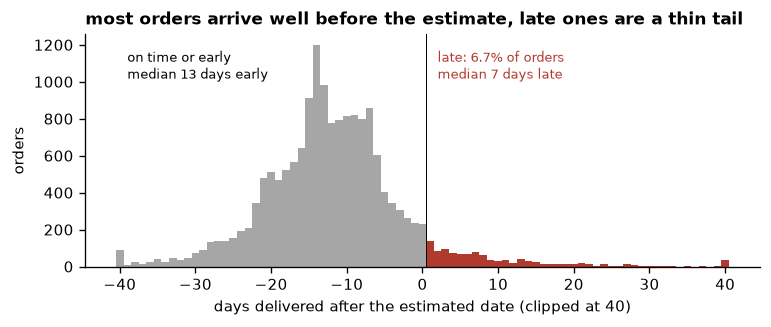

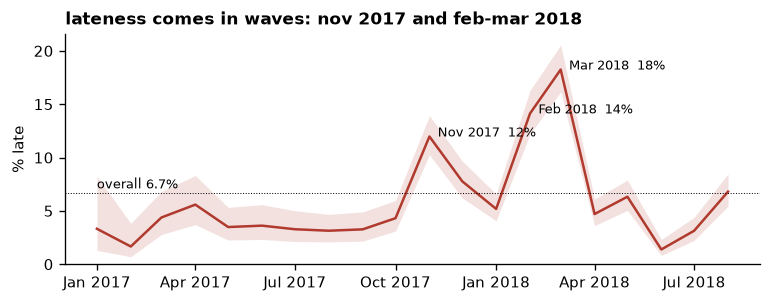

In [15]:
late = lab.days_late[lab.days_late > 0]
q1 = late.describe(percentiles=[.25, .5, .75, .9]).round(1)
print(q1.to_dict(), "| late by more than a week:", round((late > 7).mean(), 3), "| median days early, on time orders:", -lab.days_late[lab.late == 0].median())

counts = lab.days_late.clip(-40, 40).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.bar(counts.index, counts.values, width=1, color=[RED if x > 0 else GREY for x in counts.index])
ax.axvline(0.5, color="black", lw=0.6)
ax.text(2, counts.max() * 0.85, f"late: {overall:.1%} of orders\nmedian {late.median():.0f} days late", color=RED, fontsize=8)
ax.text(-39, counts.max() * 0.85, f"on time or early\nmedian {-lab.days_late[lab.late == 0].median():.0f} days early", fontsize=8)
ax.set(xlabel="days delivered after the estimated date (clipped at 40)", ylabel="orders")
ax.set_title("most orders arrive well before the estimate, late ones are a thin tail")
save(fig, OUT / "q1_days_vs_estimate.png")
counts.rename("orders").to_csv(OUT / "q1_days_vs_estimate.csv")
q1.rename("days").to_csv(OUT / "q1_delay_among_late.csv")

q1m = rate(lab, "month").query("orders >= 100")  # the first months of 2016 have a handful of orders
fig, ax = plt.subplots(figsize=(6.5, 2.6))
x = pd.to_datetime(q1m.month)
ax.fill_between(x, q1m.ci_low * 100, q1m.ci_high * 100, color=RED, alpha=0.15, lw=0)
ax.plot(x, q1m.late_rate * 100, color=RED, lw=1.5)
ax.axhline(overall * 100, color="black", lw=0.6, ls=":")
ax.text(x.iloc[0], overall * 100 + 0.4, f"overall {overall:.1%}", fontsize=8)
for _, r in q1m.nlargest(3, "late_rate").iterrows():
    ax.annotate(f"{pd.to_datetime(r.month):%b %Y}  {r.late_rate:.0%}", (pd.to_datetime(r.month), r.late_rate * 100), xytext=(5, 0), textcoords="offset points", fontsize=8)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set(ylabel="% late", ylim=(0, None))
ax.set_title("lateness comes in waves: nov 2017 and feb-mar 2018")
save(fig, OUT / "q1_late_by_month.png")
q1m.to_csv(OUT / "q1_late_by_month.csv", index=False)

### q2 - time from approval to the estimated date

lead time = estimated date minus approval time. grouped by week so each group has enough orders.

no approval time (no lead time): 312 | spearman lead days vs days late: -0.565


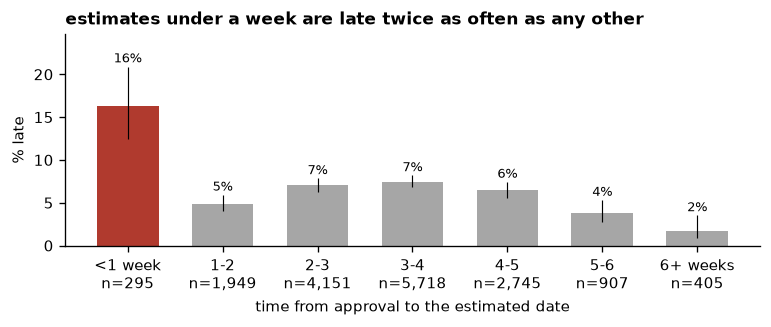

short estimates in the 3 spike months        0.000
short orders compared                      276.000
late rate, short                             0.163
late rate, longer, same state and month      0.042
dtype: float64

In [16]:
q2 = rate(lab.dropna(subset=["lead_week"]), "lead_week")
print("no approval time (no lead time):", lab.lead_days.isna().sum(), "| spearman lead days vs days late:", round(lab[["lead_days", "days_late"]].corr("spearman").iloc[0, 1], 3))

fig, ax = plt.subplots(figsize=(6.5, 2.8))
xs = np.arange(len(q2))
ax.bar(xs, q2.late_rate * 100, color=[RED] + [GREY] * (len(q2) - 1), width=0.65)
ax.vlines(xs, q2.ci_low * 100, q2.ci_high * 100, color="black", lw=0.7)
for i, r in q2.iterrows():
    ax.text(i, r.ci_high * 100 + 0.5, f"{r.late_rate:.0%}", ha="center", fontsize=8)
ax.set_xticks(xs, [f"{a}\nn={n:,}" for a, n in zip(WEEKS, q2.orders)]); ax.set_ylim(0, q2.ci_high.max() * 118)
ax.set(xlabel="time from approval to the estimated date", ylabel="% late")
ax.set_title("estimates under a week are late twice as often as any other")
save(fig, OUT / "q2_late_by_lead_time.png")
q2.to_csv(OUT / "q2_late_by_lead_time.csv", index=False)

# is it really state or season? compare short and longer estimates inside the same state and the same month
s = lab.dropna(subset=["lead_days", "customer_state"]).assign(short=lambda d: d.lead_days < 7)
g = s.groupby(["customer_state", "month", "short"]).late.agg(["size", "mean"]).unstack("short").dropna()
w = g[("size", True)]
q2s = pd.Series({"short estimates in the 3 spike months": int((s.short & s.month.isin(SPIKE)).sum()),
                 "short orders compared": int(w.sum()),
                 "late rate, short": round((g[("mean", True)] * w).sum() / w.sum(), 3),
                 "late rate, longer, same state and month": round((g[("mean", False)] * w).sum() / w.sum(), 3)})
q2s.rename("value").to_csv(OUT / "q2_within_state_month.csv")
q2s

### q3 - late rate by customer state, where to look first

a high rate on a handful of orders is mostly noise, a slightly raised rate on thousands of orders is a lot of late deliveries. so states are ranked by **excess late orders** = late orders - what the overall rate predicts for that many orders. that is how many late deliveries fixing the state could remove.

labelled orders with no state: 951 | states whose interval sits fully above or below overall: 12 of 27 (1-2 expected by chance at 95%)


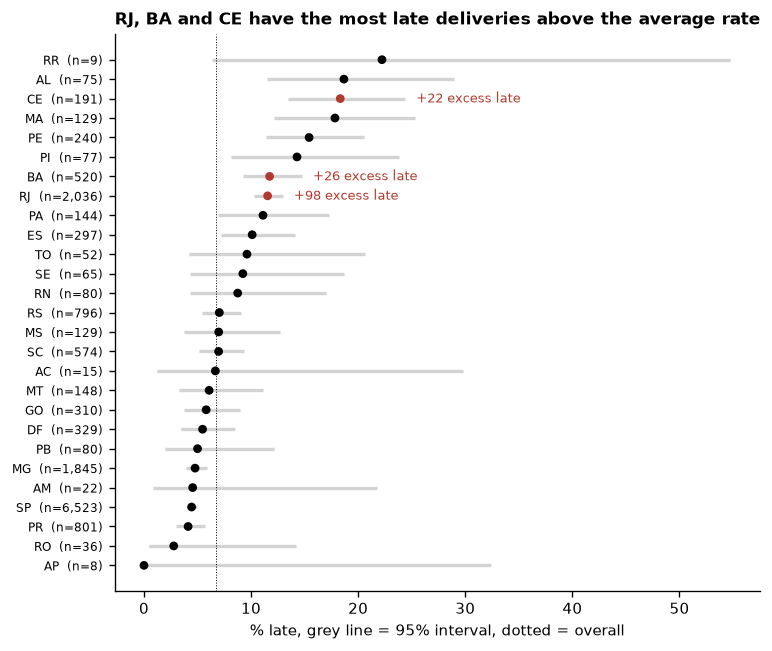

,customer_state,orders,late,late_rate,ci_low,ci_high,excess_late,excess_late_outside_spikes
0,RJ,2036,235,0.115,0.102,0.130,98.254,29.061
1,BA,520,61,0.117,0.092,0.148,26.075,24.642
2,CE,191,35,0.183,0.135,0.244,22.172,7.291
3,PE,240,37,0.154,0.114,0.205,20.881,15.569
4,MA,129,23,0.178,0.122,0.253,14.336,5.603
5,ES,297,30,0.101,0.072,0.141,10.052,4.212


In [17]:
st3 = rate(lab.dropna(subset=["customer_state"]), "customer_state")
st3["excess_late"] = st3.late - st3.orders * overall
spike = lab.month.isin(SPIKE)
calm = rate(lab[~spike].dropna(subset=["customer_state"]), "customer_state").set_index("customer_state")
st3["excess_late_outside_spikes"] = st3.customer_state.map(calm.late - calm.orders * lab.late[~spike].mean())
st3 = st3.sort_values("excess_late", ascending=False).reset_index(drop=True)
print("labelled orders with no state:", lab.customer_state.isna().sum(),
      "| states whose interval sits fully above or below overall:", int(((st3.ci_low > overall) | (st3.ci_high < overall)).sum()), "of", len(st3),
      "(1-2 expected by chance at 95%)")

p = st3.sort_values("late_rate")
top = set(st3.customer_state[:3])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
y = np.arange(len(p))
ax.hlines(y, p.ci_low * 100, p.ci_high * 100, color="lightgray", lw=2)
ax.scatter(p.late_rate * 100, y, color=[RED if s in top else "black" for s in p.customer_state], s=18, zorder=3)
ax.axvline(overall * 100, color="black", lw=0.6, ls=":")
ax.set_yticks(y, [f"{s}  (n={n:,})" for s, n in zip(p.customer_state, p.orders)], fontsize=7)
for _, r in p[p.customer_state.isin(top)].iterrows():
    ax.text(r.ci_high * 100 + 1, y[p.customer_state.tolist().index(r.customer_state)], f"+{r.excess_late:.0f} excess late", color=RED, va="center", fontsize=8)
ax.set_xlabel("% late, grey line = 95% interval, dotted = overall")
ax.set_title("RJ, BA and CE have the most late deliveries above the average rate")
save(fig, OUT / "q3_late_by_state.png")
st3.to_csv(OUT / "q3_late_by_state.csv", index=False)
st3.head(6).round(3)

within the top states, where does it come from? excess late orders split by month (spike vs rest) and by where the seller is:

In [18]:
items = read("02_clean/items_clean")
seller = items.groupby("order_id").seller_state.agg(lambda x: x.mode().iloc[0] if x.notna().any() else None)
lab["seller_state"] = lab.order_id.map(seller)
lab["seller_side"] = ("seller in " + lab.seller_state).fillna("seller unknown").mask((lab.seller_state == lab.customer_state).fillna(False).astype(bool), "seller in same state")
lab["months"] = np.where(spike, "spike months", "other months")
base = {"months": lab.groupby("months").late.mean(), "seller_side": pd.Series(overall, index=lab.seller_side.unique())}  # expected rate for each group
drill = []
for state in st3.customer_state[:3]:
    d = lab[lab.customer_state == state]
    for col in ["months", "seller_side"]:
        r = d.groupby(col).late.agg(orders="size", late="sum")
        r["late_rate"] = r.late / r.orders
        r["excess_late"] = r.late - r.orders * base[col].reindex(r.index)
        drill.append(r.assign(state=state, split=col).rename_axis("group").reset_index())
drill = pd.concat(drill).query("orders >= 30").sort_values(["state", "split", "excess_late"], ascending=[True, True, False])
drill.to_csv(OUT / "q3_drilldown.csv", index=False)
drill.groupby(["state", "split"]).head(3).round(3)

,group,orders,late,late_rate,excess_late,state,split
0,other months,405,43,0.106,24.642,BA,months
1,spike months,115,18,0.157,0.996,BA,months
10,seller in SP,346,47,0.136,23.761,BA,seller_side
4,seller in MG,51,5,0.098,1.575,BA,seller_side
12,seller unknown,33,3,0.091,0.784,BA,seller_side
1,spike months,43,21,0.488,14.642,CE,months
0,other months,148,14,0.095,7.291,CE,months
8,seller in SP,133,24,0.180,15.067,CE,seller_side
1,spike months,471,135,0.287,65.356,RJ,months
0,other months,1565,100,0.064,29.061,RJ,months


### how much the answers depend on which orders are included

each row changes one choice from step 2 and recomputes the headline numbers:
- `+ not_reported` labels the 780 of the 804 status-unknown orders that have usable dates
- `+ 7 day shift undone` moves the deliveries dated exactly 7 days before approval forward 7 days and labels them
- `no recovered states` drops states recovered from the zip
- `no missing prices` only orders where every price and freight is known

In [19]:
def headline(df):
    q2v = rate(df.dropna(subset=["lead_week"]), "lead_week").set_index("lead_week").late_rate
    s3 = rate(df.dropna(subset=["customer_state"]), "customer_state")
    s3["x"] = s3.late - s3.orders * df.late.mean()
    lo, hi = wilson(df.late.sum(), len(df))
    return {"orders": len(df), "late_rate": round(df.late.mean(), 4), "ci": f"{lo:.3f}-{hi:.3f}", "median_days_late": df.days_late[df.late == 1].median(),
            "late_<1_week": round(q2v["<1 week"], 3), "late_4-5_weeks": round(q2v["4-5"], 3), "top3_states": " ".join(s3.nlargest(3, "x").customer_state)}

def relabel(df, dl):
    df = df.copy()
    df["days_late"] = (dl.dt.normalize() - df.order_estimated_delivery_date.dt.normalize()).dt.days
    df["late"] = (df.days_late > 0).astype(int)
    return add_lead(df)[df.order_estimated_delivery_date.notna()]

dlv, apv = o.order_delivered_customer_date, o.order_approved_at
nr = o[(o.unlabelled_reason == "status unknown") & dlv.notna() & ~(dlv < apv) & ~(dlv < o.order_purchase_timestamp)]
sh = o[(o.unlabelled_reason == "delivery dated before purchase or approval") & (o.order_status == "delivered") & ((apv - dlv) == pd.Timedelta(days=7))]
sens = pd.DataFrame({
    "baseline": headline(lab),
    "+ not_reported": headline(pd.concat([lab, relabel(nr, nr.order_delivered_customer_date)])),
    "+ 7 day shift undone": headline(pd.concat([lab, relabel(sh, sh.order_delivered_customer_date + pd.Timedelta(days=7))])),
    "no recovered states": headline(lab[~lab.customer_state_recovered]),
    "no missing prices": headline(lab[(lab.n_price_null == 0) & (lab.n_freight_null == 0)]),
}).T
k, n, c = lab.late.sum(), len(lab), (o.unlabelled_reason == "cancelled or unavailable").sum()
cancelled = o[o.unlabelled_reason == "cancelled or unavailable"]
print(f"cancelled/unavailable: {c}, of which already with the carrier: {cancelled.order_delivered_carrier_date.notna().sum()}")
print(f"late rate if none of them would have been late {k / (n + c):.4f}, if all of them {(k + c) / (n + c):.4f}")
sens.to_csv(OUT / "sensitivity.csv")
sens

cancelled/unavailable: 944, of which already with the carrier: 743
late rate if none of them would have been late 0.0635, if all of them 0.1177


,orders,late_rate,ci,median_days_late,late_<1_week,late_4-5_weeks,top3_states
baseline,16482,0.0672,0.063-0.071,7.0,0.163,0.064,RJ BA CE
+ not_reported,17262,0.0679,0.064-0.072,7.0,0.165,0.067,RJ BA CE
+ 7 day shift undone,17264,0.0641,0.061-0.068,7.0,0.161,0.061,RJ BA CE
no recovered states,15757,0.0672,0.063-0.071,7.0,0.166,0.065,RJ BA CE
no missing prices,15775,0.0673,0.063-0.071,7.0,0.171,0.064,RJ BA CE


### answers

**q1.** about 1 in 15 labelled orders arrives late (6.7%, 95% interval 6.3-7.1%). a late order is typically a week late (median 7 days, middle half 3-13) with a long tail, 1 in 8 is 3+ weeks late. the typical on-time order arrives 13 days early, so estimates are padded. lateness comes in waves: orders bought in march 2018 were late 18% of the time, february 2018 14%, november 2017 (black friday) 12%, against 1-8% in other months. the data doesnt say why.

**q2.** estimates under a week are late 16% of the time, twice any other group. from 1 to 5 weeks it sits at 5-7%, beyond 6 weeks under 2%. the obvious worry is that short estimates just come from certain states or months. they dont explain it: none of the short estimates fall in the spike months, and inside the same state and month short estimates are late 16.3% vs 4.2%. still an association, seller, product or carrier could sit behind it. so it doesnt say a longer estimate would make deliveries faster, but the estimate is a useful risk signal at approval.

**q3.** investigate rio de janeiro (RJ) first, then bahia (BA) and ceara (CE). RJ's rate (11.5%) is not the highest, but on 2,000+ orders it means about 98 more late deliveries than the average rate predicts, with a tight interval. the drill down sharpens it: RJ's excess sits mostly in the spike months, and most of it is on orders shipped by sellers in SP. so the first thing to look at is the SP -> RJ route at peak times. BA keeps an excess outside the spikes too, a steadier problem. RR and AP look extreme but rest on under 10 orders. with 27 states 1-2 would sit outside the overall rate by chance, 12 do, so states really differ. 951 labelled orders (6%) have no state, 741 of them because the customer row is missing, so they are left out of this ranking.

**data quality and confidence.** the numbers barely move when the cleaning choices change. every variant gives 6.4-6.8% and the same top 3 states. the real gap is coverage: 18% of orders have no label. the 944 cancelled ones could move the late rate anywhere from 6.4% (none would have been late) to 11.8% (all would have). 743 of them were already with the carrier, so lateness may have played a part, and 6.7% is best read as a lower end. this is one modified extract from 2016-2018, so RJ, BA, CE, the spike months and under-a-week estimates are where to look first, not proven causes.

In [20]:
done(in_memory_MB={"orders": size(o), "labelled": size(lab), "items": size(items)})

{'step': '03_eda',
 'seconds': 1.62,
 'rss_start_MB': 319.67,
 'rss_peak_MB': 389.23,
 'rss_peak_above_start_MB': 69.57,
 'in_memory_MB': {'orders': np.float64(6.56),
  'labelled': np.float64(6.85),
  'items': np.float64(7.97)},
 'saved_MB': {'q1_days_vs_estimate.csv': 0.0,
  'q1_days_vs_estimate.png': 0.03,
  'q1_delay_among_late.csv': 0.0,
  'q1_late_by_month.csv': 0.0,
  'q1_late_by_month.png': 0.04,
  'q2_late_by_lead_time.csv': 0.0,
  'q2_late_by_lead_time.png': 0.02,
  'q2_within_state_month.csv': 0.0,
  'q3_drilldown.csv': 0.0,
  'q3_late_by_state.csv': 0.0,
  'q3_late_by_state.png': 0.06,
  'sensitivity.csv': 0.0}}

## step 4 - features

in: `data/02_clean/*_clean.parquet`. out, in `data/04_features/`: `features.parquet` (numbers only, no id, no label), `ids_labels.parquet` (`order_id`, `delivered_after_estimate`, same row order), `feature_descriptions.csv`, `leakage_check.csv`, `baseline_model.csv`

rows: the 16,482 labelled orders, a model cant learn from orders without a reliable label. only what is known at approval (brief): basket, prices, freight, estimated date, customer location, product and seller attributes, purchase and approval time. never payments, status, carrier or delivery dates, reviews, `shipping_limit_date`. those columns are dropped before anything is built, so using one by mistake fails.

representation:
- counts and sums per order, since the label is per order
- missing stays NaN with a `_missing` flag. a median filled in here would be computed from every order, including ones a model is later tested on. imputing belongs to model fitting
- customer state one hot (27 + missing). category of the most expensive item one hot, top 15 + other + missing, rare categories would be near-empty columns
- month, weekday, hour as sin + cos, so december sits next to january and 23h next to 0h
- no year: a model runs on future orders, a year it never saw tells it nothing

estimate: under a second, 30-60 MB above start, under 2 MB saved.

In [21]:
OUT, done = track("04_features")
o = read("02_clean/orders_clean")
it = read("02_clean/items_clean")
lab = o[o.unlabelled_reason.isna()].set_index("order_id")
y, days_late = lab.delivered_after_estimate.astype(int), lab.days_late
FORBIDDEN = ["payment", "order_status", "carrier", "delivered_customer", "review", "shipping_limit"]
gone = [c for c in o.columns if any(w in c for w in FORBIDDEN)] + ["delivered_after_estimate", "days_late", "unlabelled_reason"]
lab = lab.drop(columns=gone)
it = it.drop(columns=["shipping_limit_date"])
it = it[it.order_id.isin(lab.index)].join(lab.customer_state, on="order_id")
print("dropped before building:", gone)

ap, es = lab.order_approved_at, lab.order_estimated_delivery_date
pu = lab.order_purchase_timestamp.fillna(ap)  # 2018-02-30 left some purchase times missing, approval is the same day or close
f = pd.DataFrame(index=lab.index)
f["lead_days"] = days(es - ap)
f["approval_hours"] = days(ap - lab.order_purchase_timestamp) * 24
for name, x, period in [("month", pu.dt.month - 1, 12), ("weekday", pu.dt.dayofweek, 7), ("hour", pu.dt.hour, 24)]:
    f[f"purchase_{name}_sin"], f[f"purchase_{name}_cos"] = np.sin(2 * np.pi * x / period), np.cos(2 * np.pi * x / period)
f["n_items"], f["n_products"], f["n_sellers"] = lab.n_items, lab.n_products, lab.n_sellers
f["price_sum"] = lab.price_sum.where(lab.n_price_null == 0)  # a sum with a missing price would be too low
f["freight_sum"] = lab.freight_sum.where(lab.n_freight_null == 0)
f["freight_share"] = f.freight_sum / (f.price_sum + f.freight_sum)

it["volume_cm3"] = it.product_length_cm * it.product_height_cm * it.product_width_cm
it["same_state"] = (it.seller_state == it.customer_state).astype("float64")
g = it.groupby("order_id")
whole = lambda c: g[c].sum().where(~it[c].isna().groupby(it.order_id).any())  # missing if any item is missing
f["weight_g_sum"], f["volume_cm3_sum"] = whole("product_weight_g"), whole("volume_cm3")
f["photos_mean"] = g.product_photos_qty.mean()
f["n_seller_states"] = g.seller_state.nunique()
f["share_items_same_state"] = g.same_state.mean()

main = it.sort_values("price", ascending=False).drop_duplicates("order_id").set_index("order_id")
cat = main.product_category_name_english.fillna(main.product_category_name).reindex(lab.index)
cat = cat.where(cat.isin(cat.value_counts().index[:15]) | cat.isna(), "other").fillna("missing")
f = f.astype("float64")
for c in ["lead_days", "approval_hours", "price_sum", "freight_sum", "weight_g_sum", "volume_cm3_sum", "photos_mean", "share_items_same_state"]:
    f[f"{c}_missing"] = f[c].isna().astype("float64")
f = f.join(pd.get_dummies(lab.customer_state.fillna("missing"), prefix="state", dtype="float64"))
f = f.join(pd.get_dummies(cat, prefix="cat", dtype="float64"))
print(f.shape, "| all float:", (f.dtypes == "float64").all())
f.describe().T[["count", "mean", "min", "max"]].round(2).head(22)

dropped before building: ['order_status', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'n_payments', 'payment_sum_centavos', 'n_payment_null', 'n_reviews', 'delivered_after_estimate', 'days_late', 'unlabelled_reason']
(16482, 72) | all float: True


,count,mean,min,max
lead_days,16170.0,23.27,0.86,101.00
approval_hours,15843.0,10.05,0.00,741.44
purchase_month_sin,16482.0,0.13,-1.00,1.00
purchase_month_cos,16482.0,-0.06,-1.00,1.00
purchase_weekday_sin,16482.0,0.07,-0.97,0.97
purchase_weekday_cos,16482.0,0.01,-0.90,1.00
purchase_hour_sin,16482.0,-0.33,-1.00,1.00
purchase_hour_cos,16482.0,-0.22,-1.00,1.00
n_items,16482.0,1.14,1.00,21.00
n_products,16482.0,1.05,1.00,8.00


### which features to keep

two dropped while building, both near copies of a kept one:
- `est_days_from_purchase` = `lead_days` + `approval_hours` / 24, an exact sum of two kept features
- `n_categories` was 0 exactly when the category is missing (`cat_missing`) and 1 almost everywhere else

the rest are kept. each is known at approval, means something different, and no pair is a near copy (checked below). choosing features by how well they predict the label is left to model fitting, with cross validation on training data only. choosing them here on all labelled orders would let the test orders pick the features.

In [22]:
corr = f.drop(columns=f.filter(like="_missing").columns).corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False)
print("most correlated pairs:"); print(pairs.head(4).round(3))

most correlated pairs:
weight_g_sum            volume_cm3_sum    0.782
share_items_same_state  state_SP          0.704
freight_sum             volume_cm3_sum    0.616
                        weight_g_sum      0.615
dtype: float64


### leakage check

1. the forbidden columns were dropped before building, and every feature lists its source columns below. none of them is forbidden.
2. each feature on its own is scored against the label with roc auc: 0.5 = no signal, near 0 or 1 = splits late from on time almost perfectly, which for a single feature almost always means it contains the outcome. `days_late` (the outcome, never a feature) is scored as a control. it should come out at 1.0, which shows the check can catch a leak.

In [23]:
DESC = {
    "lead_days": ("days from approval to the estimated delivery date", "order_approved_at, order_estimated_delivery_date"),
    "approval_hours": ("hours from purchase to approval", "order_purchase_timestamp, order_approved_at"),
    "purchase_month": ("purchase month on a circle (sin, cos). approval time when purchase time is missing", "order_purchase_timestamp"),
    "purchase_weekday": ("purchase weekday on a circle (sin, cos)", "order_purchase_timestamp"),
    "purchase_hour": ("purchase hour on a circle (sin, cos)", "order_purchase_timestamp"),
    "n_items": ("items in the order", "order_items"),
    "n_products": ("different products", "order_items.product_id"),
    "n_sellers": ("different sellers", "order_items.seller_id"),
    "price_sum": ("total item price BRL, missing if any price is missing", "order_items.price"),
    "freight_sum": ("total freight BRL, missing if any freight is missing", "order_items.freight_value"),
    "freight_share": ("freight / (price + freight)", "order_items.price, order_items.freight_value"),
    "weight_g_sum": ("total product weight in grams, missing if any is missing", "products.product_weight_g"),
    "volume_cm3_sum": ("total product volume (length x height x width) cm3", "products.product_*_cm"),
    "photos_mean": ("mean product photos", "products.product_photos_qty"),
    "n_seller_states": ("different seller states", "sellers.seller_state"),
    "share_items_same_state": ("share of items whose seller is in the customer's state", "sellers.seller_state, customers.customer_state"),
    "state": ("customer state is", "customers.customer_state"),
    "cat": ("category of the most expensive item is (top 15, other, missing)", "products.product_category_name, category_translation"),
}
def describe(c):
    base = c.removesuffix("_missing").removesuffix("_sin").removesuffix("_cos")
    key = base if base in DESC else c.split("_")[0]
    meaning, source = DESC[key]
    if c.endswith("_missing"):
        meaning = f"1 if {base} is missing"
    elif key in ("state", "cat"):
        meaning = f"1 if {meaning} {c.split('_', 1)[1]}"
    return c, meaning, source
desc = pd.DataFrame(map(describe, f.columns), columns=["feature", "meaning", "source_columns"])
assert not desc.source_columns.str.contains("|".join(FORBIDDEN)).any()

def auc(x):
    m = x.notna()
    r, pos = x[m].rank(), y[m] == 1
    return (r[pos].sum() - pos.sum() * (pos.sum() + 1) / 2) / (pos.sum() * (~pos).sum())
leak = pd.DataFrame({"auc": f.apply(auc), "non_missing": f.notna().sum()})
leak.loc["days_late (control, not a feature)"] = [auc(days_late.astype("float64")), days_late.notna().sum()]
leak = leak.reindex((leak.auc - 0.5).abs().sort_values(ascending=False).index).round(3)
print("features beyond 0.2-0.8:", leak.drop("days_late (control, not a feature)").query("abs(auc - 0.5) > 0.3").index.tolist())
leak.head(8)

features beyond 0.2-0.8: []


,auc,non_missing
"days_late (control, not a feature)",1.000,16482.0
purchase_month_cos,0.611,16482.0
state_SP,0.428,16482.0
share_items_same_state,0.436,14781.0
freight_sum,0.559,16150.0
state_RJ,0.548,16482.0
weight_g_sum,0.535,15019.0
price_sum,0.532,16103.0


In [24]:
f.reset_index(drop=True).to_parquet(OUT / "features.parquet")
ids = y.rename("delivered_after_estimate").reset_index()
assert (ids.order_id == f.index).all() and ids.order_id.is_unique
ids.to_parquet(OUT / "ids_labels.parquet", index=False)
desc.to_csv(OUT / "feature_descriptions.csv", index=False)
leak.to_csv(OUT / "leakage_check.csv")
done(in_memory_MB={"orders": size(o), "items": size(it), "features": size(f)})

{'step': '04_features',
 'seconds': 0.25,
 'rss_start_MB': 389.22,
 'rss_peak_MB': 447.81,
 'rss_peak_above_start_MB': 58.59,
 'in_memory_MB': {'orders': np.float64(6.56),
  'items': np.float64(6.77),
  'features': np.float64(10.68)},
 'saved_MB': {'baseline_model.csv': 0.0,
  'feature_descriptions.csv': 0.01,
  'features.parquet': 0.64,
  'ids_labels.parquet': 0.57,
  'leakage_check.csv': 0.0}}

### do the features carry signal? a baseline model

not the deliverable, a check on it. a gradient boosted tree (handles NaN itself) is trained on orders bought before 2018-04 and tested on the later ones, the way it would be used: learn from the past, predict the future. the same model with `days_late` added is the leak control. it should score near 1.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
t0 = time.perf_counter()
train = (pu < "2018-04-01").values
m = lambda X: HistGradientBoostingClassifier(random_state=0).fit(X[train], y[train]).predict_proba(X[~train])[:, 1]
model = pd.Series({
    "lead_days only": roc_auc_score(y[~train], m(f[["lead_days"]])),
    "all features": roc_auc_score(y[~train], m(f)),
    "all features + days_late (leak control)": roc_auc_score(y[~train], m(f.assign(days_late=days_late.astype("float64")))),
}, name="test auc").round(3)
print(f"train {train.sum()} orders, test {(~train).sum()} orders, test late rate {y[~train].mean():.3f}, 3 fits in {time.perf_counter() - t0:.0f} s (not in step 4's numbers)")
model.to_csv(OUT / "baseline_model.csv")
model

train 11005 orders, test 5477 orders, test late rate 0.045, 3 fits in 1 s (not in step 4's numbers)


lead_days only                             0.534
all features                               0.611
all features + days_late (leak control)    1.000
Name: test auc, dtype: float64

a test auc of 0.61 is modest. it is clearly above chance and above lead time alone (0.53), and far below the leak control (1.0), so the features carry some signal and nothing leaks. but late delivery is hard to predict from what is known at approval. part of the reason is visible in step 3: much of the lateness comes in waves (feb-mar 2018) that a model trained on the past cant see coming, and the test months (apr-aug 2018, 4.5% late) are calm. this is a check on the features, not a tuned model.

## step 5 - resources and environment

`uv run python run.py` rebuilds everything: checks the supplied files against `supplied.sha256`, rebuilds the db with the supplied loader, runs `bench.py` and this notebook, and writes `data/manifest.sha256` with a hash of every output. two fresh runs give the same manifest, so the outputs are reproduced byte for byte. timing files are left out, timings always differ. `run.py --fast` skips the engine comparison (about 5 minutes) and reuses its last result.

scope of the numbers:
- runtime: wall clock of the step in this kernel
- memory: this kernel's rss sampled every 10 ms during the step. `above_start` is what the step added, `start` includes python, pandas and earlier steps' data. step 0 runs in its own process (`run.py`), so its peak is that whole process and it has no start
- saved: the step's output files on disk. temporary: files that exist only while the step runs

estimate rules, from the size of the data each step holds in memory:
- memory: peak above start ~ 2-3x that size (pandas makes a copy or two filtering and joining). step 0: python (~15 MB) + the sql text, which the supplied loader reads whole, + up to that again for sqlite
- saved storage: parquet keeps ~0.3-0.5x the in-memory size of the tables a step writes (columns compressed, repeated strings stored once). step 3 writes only charts and small csvs, under 1 MB. step 0: the db ~1-1.5x the sql text (indexes on top of the rows)
- runtime: steps 1, 2 and 4 are a few vectorised passes over ~20 MB, under 1 s. step 3 also draws 4 charts, 1-3 s. step 0 runs 117k inserts, under 5 s
- intermediate data: each step's parquet outputs are the next step's input, so `saved_MB` is also the intermediate data

In [26]:
OUT, done = track("05_resources")
res = pd.DataFrame([json.loads(p.read_text()) for p in sorted(DATA.glob("0[0-4]*/resources.json"))]).set_index("step")
res["data_MB"] = res.in_memory_MB.apply(lambda d: round(sum(d.values()), 1))
res["estimate_MB"] = res.data_MB.apply(lambda m: f"{2 * m:.0f}-{3 * m:.0f}")
res.loc["00_setup_db", "estimate_MB"] = res.estimate_peak_MB["00_setup_db"]  # whole process, see run.py
res["saved_MB"] = res.saved_MB.apply(lambda d: round(sum(d.values()), 2))
written = {"00_setup_db": ["raw.sql text"], "01_load": ["orders", "items"], "02_clean": ["orders", "items", "changes"], "04_features": ["features"]}  # tables each step saves
k = {"00_setup_db": (1, 1.5)}
res["estimate_saved_MB"] = [f"{k.get(s, (.3, .5))[0] * m:.1f}-{k.get(s, (.3, .5))[1] * m:.1f}" if (m := sum(res.in_memory_MB[s][t] for t in written.get(s, []))) else "<1" for s in res.index]
res["estimate_seconds"] = pd.Series({"00_setup_db": "<5", "01_load": "<1", "02_clean": "<1", "03_eda": "1-3", "04_features": "<1"})
bench = pd.read_csv(DATA / "01_load" / "bench.csv")
res.loc["01_load", "temporary_MB"] = bench.sqlite_MB.max() + bench.parquet_MB.max()
summary = res[["seconds", "estimate_seconds", "rss_start_MB", "rss_peak_MB", "rss_peak_above_start_MB", "data_MB", "estimate_MB", "saved_MB", "estimate_saved_MB", "temporary_MB"]]
summary.to_csv(OUT / "resources_summary.csv")
summary

,seconds,estimate_seconds,rss_start_MB,rss_peak_MB,rss_peak_above_start_MB,data_MB,estimate_MB,saved_MB,estimate_saved_MB,temporary_MB
step,,,,,,,,,,
00_setup_db,2.22,<5,NaN,205.39,NaN,18.3,33-52,24.36,18.3-27.4,NaN
01_load,0.22,<1,164.72,235.52,70.80,12.9,26-39,5.19,3.9-6.4,297.99
02_clean,0.57,<1,253.84,319.70,65.86,17.6,35-53,6.55,5.3-8.8,NaN
03_eda,1.62,1-3,319.67,389.23,69.57,21.4,43-64,0.15,<1,NaN
04_features,0.25,<1,389.22,447.81,58.59,24.0,48-72,1.22,3.2-5.3,NaN


steps 3 and 4 land inside or right at their estimates. steps 1 and 2 went over it, using 4-6x their data. the rule counts only the dataframes. the likely gap (not measured on its own) is the arrow buffers adbc hands over before pandas wraps them, and rss keeping memory pandas has freed but not returned to the os. for steps that read from the db, 4-6x the data is the better rule. the numbers also move a little between runs (rss depends on when memory goes back to the os), so read them as sizes, not exact values. every notebook step stays under 100 MB above start and under 2 seconds, and the 10x comparison in step 1 shows loading stays small as the data grows. `temporary_MB` there is the 10x db plus its parquet copy, deleted after the comparison.

saved storage lands inside the estimate for steps 0-3 and every step meets its runtime estimate. step 4 saved 1.2 MB against 3.2-5.3: most feature columns are one hot, almost all zeros, and parquet compresses long runs of the same value far better than the rule assumes.

step 0 was the big miss: 33-52 MB estimated, about 205 MB measured. the reviews contain emoji, and one character above U+FFFF makes python store the whole 18 million character text at 4 bytes per character (73 MB), on top of the raw bytes and the copies made while decoding. checked by hand: reading `raw.sql` as bytes peaks at 33 MB, decoding it at 123 MB, reading it as text like `setup_db.py` does at 196 MB. the loader is supplied so it stays. a loader that streams one statement at a time would need a few MB.

In [27]:
from importlib.metadata import version
import platform
env = {"python": platform.python_version(), "os": platform.platform(), "cpu_count": psutil.cpu_count(), "ram_GB": round(psutil.virtual_memory().total / 1e9, 1),
       **{p: version(p) for p in ["pandas", "numpy", "pyarrow", "adbc-driver-sqlite", "duckdb", "scikit-learn", "matplotlib"]},
       "kernel_peak_rss_MB": mb(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * (1 if sys.platform == "darwin" else 1024))}
(OUT / "environment.json").write_text(json.dumps(env, indent=1))
done()
pd.Series(env)

python                                   3.12.12
os                    macOS-27.0-arm64-arm-64bit
cpu_count                                     14
ram_GB                                      38.7
pandas                                     3.0.6
numpy                                      2.5.4
pyarrow                                   26.0.0
adbc-driver-sqlite                        1.12.0
duckdb                                     1.5.6
scikit-learn                               1.9.1
matplotlib                                3.11.2
kernel_peak_rss_MB                        557.15
dtype: object